# Reconstruction accuracy and binary encoding performance

Evaluate bVAE, ESM2 650M-bVAE, and ESM2 650M-bVAE (HPO) on Trastuzumab-scFv CDRH3 variants. The analysis compares reconstructed sequences with test sequences and relates sequence distances to Hamming distances in the binary latent space.

In [1]:
# Evaluate sequence reconstruction accuracy and binary encoding performance for Trastuzumab-scFv CDRH3 variants.
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings("ignore")

import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['axes.unicode_minus'] = False

## Load test sequences and model outputs

In [2]:
# Load test sequences and reconstructed sequences.
plm_res = "...\\pLM-bVAE\\reproduction_paper\\outputs\\"
plm_data = "...\\pLM-bVAE\\reproduction_paper\\data\\"
test_seqs = pd.read_csv(plm_data + "cdrh3\\bvae\\test.txt", sep="\t", header=None, names=["seqs"])
test_seqs["seqs"] = test_seqs["seqs"].str.replace(" ", "")
# bvae
dec_bvae = pd.read_csv(plm_res + "cdrh3_models\\bvae\\model_output\\binary\\decoded.txt", sep="\t", header=None, names=["seqs"])
dec_bvae["seqs"] = dec_bvae["seqs"].str.replace(" ", "")
# esm_650m
dec_esm_650m = pd.read_csv(plm_res + "cdrh3_models\\esm_650m\\model_output\\binary\\decoded.txt", sep="\t", header=None, names=["seqs"])
dec_esm_650m["seqs"] = dec_esm_650m["seqs"].str.replace(" ", "")
# esm_650m_opt
dec_esm_650m_opt = pd.read_csv(plm_res + "cdrh3_models\\esm_650m_opt\\model_output\\binary\\decoded.txt", sep="\t", header=None, names=["seqs"])
dec_esm_650m_opt["seqs"] = dec_esm_650m_opt["seqs"].str.replace(" ", "")

In [3]:
# Find the longest pLM-bVAE (HPO) output and display its length.
print(dec_esm_650m_opt.iloc[dec_esm_650m_opt['seqs'].str.len().idxmax()]["seqs"])
print(len(dec_esm_650m_opt.iloc[dec_esm_650m_opt['seqs'].str.len().idxmax()]["seqs"]))

CSRYGWAHIWAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQ
100


In [4]:
# Select pLM-bVAE (HPO) outputs of length 100.
print(dec_esm_650m_opt.iloc[dec_esm_650m_opt['seqs'].str.len().idxmax()])
# Remove row 841 from pLM-bVAE (HPO) outputs.
dec_esm_650m_opt_dp = dec_esm_650m_opt.drop(dec_esm_650m_opt.index[841])

# Remove row 841 from the test sequences.
test_seqs_dp = test_seqs.drop(test_seqs.index[841])

seqs    CSRYGWAHIWAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQAQ...
Name: 841, dtype: object


## Levenshtein reconstruction accuracy

In [5]:
# Calculate Levenshtein distances between test and decoded sequences.
import Levenshtein
def cal_levenshtein_dist(test_seqs, decoded_seqs):
    lev_distances = []
    for original, decoded in zip(test_seqs["seqs"], decoded_seqs["seqs"]):
        dist = Levenshtein.distance(original, decoded)
        lev_distances.append(dist)
    return lev_distances

In [6]:
# bvae
dist_bvae = cal_levenshtein_dist(test_seqs, dec_bvae)
# esm_650m
dist_esm_650m = cal_levenshtein_dist(test_seqs, dec_esm_650m)
# esm_650m_opt
dist_esm_650m_opt = cal_levenshtein_dist(test_seqs_dp, dec_esm_650m_opt_dp)

In [7]:
df_Levdist = pd.DataFrame({
    "distance": np.r_[dist_bvae, dist_esm_650m, dist_esm_650m_opt],
    "series": (["bvae"] * len(dist_bvae)) + (["esm_650m"] * len(dist_esm_650m)) + (["esm_650m_opt"] * len(dist_esm_650m_opt))
})

In [8]:
df_Levdist[df_Levdist["distance"] == 0].groupby("series").size()

series
bvae            678
esm_650m        703
esm_650m_opt    927
dtype: int64

In [9]:
df_Levdist.groupby("series").size()

series
bvae            960
esm_650m        960
esm_650m_opt    959
dtype: int64

In [10]:
# Calculate the fraction of exact reconstructions for each series.
df_Levdist_zero = df_Levdist[df_Levdist["distance"] == 0].groupby("series").size() / df_Levdist.groupby("series").size()
df_Levdist_zero

series
bvae            0.706250
esm_650m        0.732292
esm_650m_opt    0.966632
dtype: float64

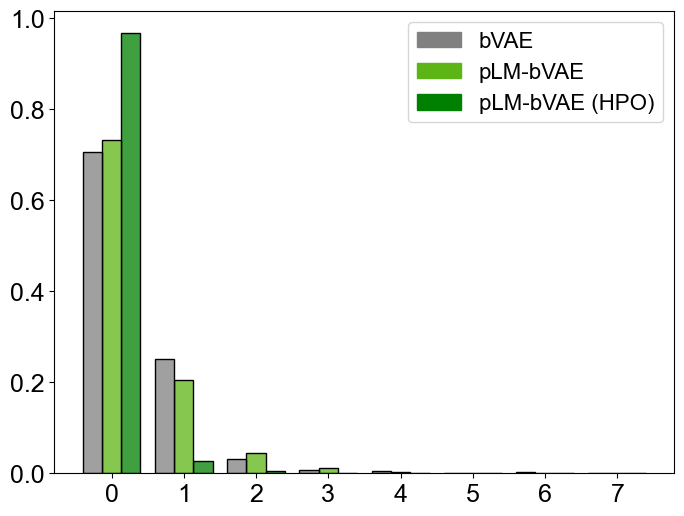

In [11]:
plt.figure(figsize=(8, 6))
mind = min(np.min(dist_bvae), np.min(dist_esm_650m), np.min(dist_esm_650m_opt))  # Calculate the minimum.
maxd = max(np.max(dist_bvae), np.max(dist_esm_650m), np.max(dist_esm_650m_opt))  # Calculate the maximum.
bins = np.arange(mind, maxd + 2) - 0.5  # Use unit-width bins centered on integers.

sns.histplot(
    data=df_Levdist, x="distance", hue="series", stat="probability", common_norm=False,
    bins=bins, multiple="dodge", shrink=0.8, discrete=True,
    palette={"bvae": "gray", "esm_650m": "#5CB514", "esm_650m_opt": "green"},
    legend=False,
)
# Set the upper limit of the horizontal axis.
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

# Specify the legend colors and labels.
handles = [
    Patch(facecolor='gray', edgecolor='gray', label='bVAE'),
    Patch(facecolor='#5CB514', edgecolor='#5CB514', label='pLM-bVAE'),
    Patch(facecolor='green', edgecolor='green', label='pLM-bVAE (HPO)'),
]
plt.legend(handles=handles, fontsize=16, title_fontsize=12, loc='upper right')

plt.xlabel('')
plt.ylabel('')
plt.show()

## BLOSUM62 reconstruction accuracy

In [12]:
# Calculate BLOSUM62 scores.
from Bio.Align import PairwiseAligner, substitution_matrices

def cal_blosum62_score(test_seqs, decoded_seqs):
    aligner = PairwiseAligner(mode="global")
    aligner.substitution_matrix = substitution_matrices.load("BLOSUM62")
    aligner.open_gap_score = -10
    aligner.extend_gap_score = -0.5

    scores = []
    for original, decoded in zip(test_seqs["seqs"], decoded_seqs["seqs"]):
        # Calculate the score without constructing the alignment.
        score = aligner.score(original, decoded)
        scores.append(score)
    return scores

In [13]:
# Calculate BLOSUM62 scores.
# bvae
b62_bvae = cal_blosum62_score(test_seqs, dec_bvae)
# esm_650m
b62_esm_650m = cal_blosum62_score(test_seqs, dec_esm_650m)
# esm_650m_opt
b62_esm_650m_opt = cal_blosum62_score(test_seqs_dp, dec_esm_650m_opt_dp)

In [14]:
df_bs62 = pd.DataFrame({
    "score": np.r_[b62_bvae, b62_esm_650m, b62_esm_650m_opt],
    "series": (["bvae"] * len(b62_bvae)) + (["esm_650m"] * len(b62_esm_650m)) + (["esm_650m_opt"] * len(b62_esm_650m_opt))
})

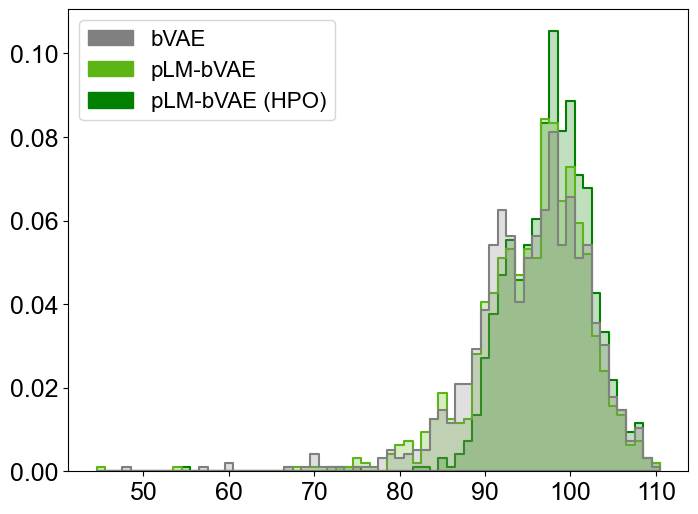

In [15]:
plt.figure(figsize=(8, 6))

min_score = int(np.floor(df_bs62["score"].min()))
max_score = int(np.ceil(df_bs62["score"].max()))
bins = np.arange(min_score, max_score + 2) - 0.5

sns.histplot(
    data=df_bs62, x="score", hue="series", stat="probability", common_norm=False,
    bins=bins, element='step', linewidth=1.5,
    palette={"bvae": "gray", "esm_650m": "#5CB514", "esm_650m_opt": "green"},
    legend=False,
)

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

# Specify the legend colors and labels.
handles = [
    Patch(facecolor='gray', edgecolor='gray', label='bVAE'),
    Patch(facecolor='#5CB514', edgecolor='#5CB514', label='pLM-bVAE'),
    Patch(facecolor='green', edgecolor='green', label='pLM-bVAE (HPO)'),
]
plt.legend(handles=handles, fontsize=16, title_fontsize=12, loc='upper left')

plt.xlabel('')
plt.ylabel('')
plt.show()

In [16]:
# Calculate the 95th percentile of bVAE BLOSUM62 scores.
bvae_top5 = np.percentile(df_bs62[df_bs62["series"] == "bvae"]["score"], 95)
bvae_top5

np.float64(105.0)

In [17]:
def top_tail_global_threshold(
    df,
    score_col="score",
    series_col="series",
):
    rows = []

    # Calculate the upper 5% threshold for bVAE scores.
    threshold = bvae_top5

    for series, sub in df.groupby(series_col):
        scores = sub[score_col].dropna()
        n_total = len(scores)

        n_top = (scores >= threshold).sum()
        frac_top = n_top / n_total

        rows.append({
            "top_percent": 5,
            "global_threshold": threshold,
            series_col: series,
            "n_total": n_total,
            "n_top": n_top,
            "fraction_top": frac_top,
        })

    return pd.DataFrame(rows)

In [18]:
global_top_tail_df = top_tail_global_threshold(
    df_bs62,
    score_col="score",
    series_col="series"
)

global_top_tail_df

,top_percent,global_threshold,series,n_total,n_top,fraction_top
0,5,105.0,bvae,960,52,0.054167
1,5,105.0,esm_650m,960,46,0.047917
2,5,105.0,esm_650m_opt,959,60,0.062565


## Sequence distances and binary encoding

In [19]:
# Define a function to calculate pairwise Levenshtein distances among test sequences.
import Levenshtein
from tqdm import tqdm
def calculate_levenshtein_distance_matrix(seqs):
    n = seqs.shape[0]
    dist_matrix_Lev = np.zeros([n, n])
    for i in tqdm(range(n)):
        for j in range(i + 1, n):
            dist = Levenshtein.distance(seqs.iloc[i]['seqs'], seqs.iloc[j]['seqs'])
            dist_matrix_Lev[i][j] = dist
            dist_matrix_Lev[j][i] = dist
    return dist_matrix_Lev

In [20]:
# Calculate the Levenshtein distance matrix.
lev_dist_mat_test_seqs = calculate_levenshtein_distance_matrix(test_seqs)

  0%|          | 0/960 [00:00<?, ?it/s]

  0%|          | 2/960 [00:00<00:52, 18.35it/s]

  1%|          | 5/960 [00:00<00:47, 20.15it/s]

  1%|          | 7/960 [00:00<00:47, 20.06it/s]

  1%|          | 10/960 [00:00<00:47, 20.18it/s]

...

 87%|████████▋ | 837/960 [00:21<00:01, 112.66it/s]

 89%|████████▉ | 852/960 [00:21<00:00, 122.28it/s]

 91%|█████████ | 871/960 [00:21<00:00, 139.84it/s]

 93%|█████████▎| 897/960 [00:22<00:00, 173.08it/s]

100%|██████████| 960/960 [00:22<00:00, 43.28it/s] 

In [21]:
# bvae
binary_bvae = pd.read_csv(plm_res + "cdrh3_models\\bvae\\model_output\\binary\\vectors.txt", sep="\t", header=None, names=["seqs"])
binary_bvae["seqs"] = binary_bvae["seqs"].str.replace(" ", "")

# esm_650m
binary_esm_650m = pd.read_csv(plm_res + "cdrh3_models\\esm_650m\\model_output\\binary\\vectors.txt", sep="\t", header=None, names=["seqs"])
binary_esm_650m["seqs"] = binary_esm_650m["seqs"].str.replace(" ", "")

# esm_650m_opt
binary_esm_650m_opt = pd.read_csv(plm_res + "cdrh3_models\\esm_650m_opt\\model_output\\binary\\vectors.txt", sep="\t", header=None, names=["seqs"])
binary_esm_650m_opt["seqs"] = binary_esm_650m_opt["seqs"].str.replace(" ", "")

In [22]:
# Define a function to calculate pairwise Hamming distances.
from Levenshtein import hamming
from tqdm import tqdm
def calculate_hamming_distance_matrix(vecs):
    n = vecs.shape[0]
    dist_matrix_ham = np.zeros([n, n])
    for i in tqdm(range(n)):
        for j in range(i + 1, n):
            dist = hamming(vecs.iloc[i]['seqs'], vecs.iloc[j]['seqs'])
            dist_matrix_ham[i][j] = dist
            dist_matrix_ham[j][i] = dist
    return dist_matrix_ham

In [23]:
# Calculate the Hamming distance matrix.
ham_dist_mat_test_seqs_bvae = calculate_hamming_distance_matrix(binary_bvae)
ham_dist_mat_test_seqs_esm_650m = calculate_hamming_distance_matrix(binary_esm_650m)
ham_dist_mat_test_seqs_esm_650m_opt = calculate_hamming_distance_matrix(binary_esm_650m_opt)

  0%|          | 0/960 [00:00<?, ?it/s]

  0%|          | 4/960 [00:00<00:38, 25.02it/s]

  1%|          | 7/960 [00:00<00:45, 20.84it/s]

  1%|          | 10/960 [00:00<00:47, 20.05it/s]

  1%|▏         | 13/960 [00:00<00:49, 19.25it/s]

...

 86%|████████▌ | 823/960 [00:25<00:00, 138.93it/s]

 88%|████████▊ | 848/960 [00:25<00:00, 168.25it/s]

 90%|█████████ | 867/960 [00:25<00:00, 173.00it/s]

 95%|█████████▍| 911/960 [00:25<00:00, 250.01it/s]

100%|██████████| 960/960 [00:25<00:00, 37.47it/s] 

In [24]:
# Flatten the upper triangle of the matrix.
lev_dist_mat_test_seqs_triu = lev_dist_mat_test_seqs[np.triu_indices_from(lev_dist_mat_test_seqs, k=1)]
ham_dist_mat_test_seqs_bvae_triu = ham_dist_mat_test_seqs_bvae[np.triu_indices_from(ham_dist_mat_test_seqs_bvae, k=1)]
ham_dist_mat_test_seqs_esm_650m_triu = ham_dist_mat_test_seqs_esm_650m[np.triu_indices_from(ham_dist_mat_test_seqs_esm_650m, k=1)]
ham_dist_mat_test_seqs_esm_650m_opt_triu = ham_dist_mat_test_seqs_esm_650m_opt[np.triu_indices_from(ham_dist_mat_test_seqs_esm_650m_opt, k=1)]

# Prepare Levenshtein distances as categories and Hamming distances as numerical values.
df_bvae = pd.DataFrame({
    "Levenshtein": lev_dist_mat_test_seqs_triu,
    "Hamming": ham_dist_mat_test_seqs_bvae_triu
})
df_esm = pd.DataFrame({
    "Levenshtein": lev_dist_mat_test_seqs_triu,
    "Hamming": ham_dist_mat_test_seqs_esm_650m_triu
})
df_esm_opt = pd.DataFrame({
    "Levenshtein": lev_dist_mat_test_seqs_triu,
    "Hamming": ham_dist_mat_test_seqs_esm_650m_opt_triu
})

# Convert Levenshtein distances to integers.
df_bvae["Levenshtein"] = df_bvae["Levenshtein"].astype(int)
df_esm["Levenshtein"] = df_esm["Levenshtein"].astype(int)
df_esm_opt["Levenshtein"] = df_esm_opt["Levenshtein"].astype(int)

In [25]:
# Calculate the Spearman correlation.
s1 = df_bvae.corr(method="spearman").iloc[0, 1]
s2 = df_esm.corr(method="spearman").iloc[0, 1]
s3 = df_esm_opt.corr(method="spearman").iloc[0, 1]

print("bvae Spearman correlation:", s1)
print("esm_650m Spearman correlation:", s2)
print("esm_650m_opt Spearman correlation:", s3)

bvae Spearman correlation: 0.4930831754280213
esm_650m Spearman correlation: 0.4427807284449016
esm_650m_opt Spearman correlation: 0.7081178256849073


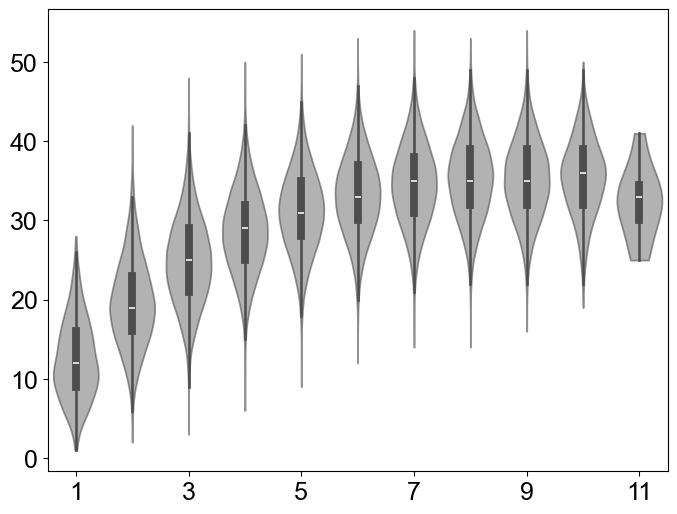

In [26]:
from matplotlib.ticker import MaxNLocator

plt.figure(figsize=(8, 6))
ax1 = sns.violinplot(x="Levenshtein", y="Hamming", data=df_bvae, cut=0, scale="width", bw_adjust=1.3,# Adjust the plot.
                     inner="box", color="gray")
# plt.ylim(-5, 60)

# plt.title('Levenshtein vs Hamming')
# Adjust transparency.
for violin in ax1.collections:
    violin.set_alpha(0.6)

# Use integer ticks on the horizontal axis.
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

# Remove axis labels.
ax1.set_xlabel("")
ax1.set_ylabel("")

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

plt.show()

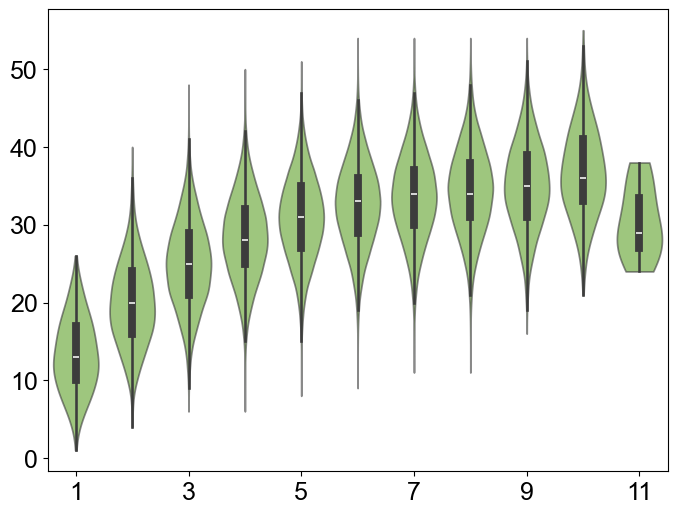

In [27]:
plt.figure(figsize=(8, 6))
ax1 = sns.violinplot(x="Levenshtein", y="Hamming", data=df_esm, cut=0, scale="width", bw_adjust=1.3,# Adjust the plot.
                     inner="box", color="#5CB514")
# plt.ylim(-5, 60)

# plt.title('Levenshtein vs Hamming')
# Adjust transparency.
for violin in ax1.collections:
    violin.set_alpha(0.6)

# Use integer ticks on the horizontal axis.
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

# Remove axis labels.
ax1.set_xlabel("")
ax1.set_ylabel("")

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

plt.show()

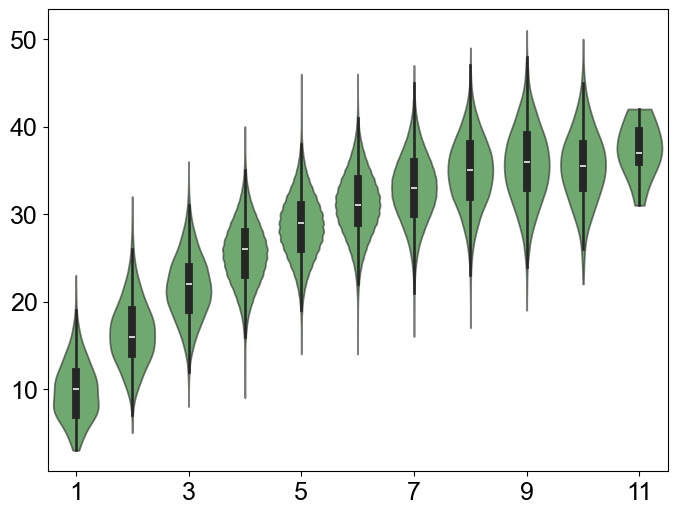

In [28]:
plt.figure(figsize=(8, 6))
ax1 = sns.violinplot(x="Levenshtein", y="Hamming", data=df_esm_opt, cut=0, scale="width", bw_adjust=1.3,# Adjust the plot.
                     inner="box", color="green")
# plt.ylim(-5, 60)

# plt.title('Levenshtein vs Hamming')
# Adjust transparency.
for violin in ax1.collections:
    violin.set_alpha(0.6)

# Use integer ticks on the horizontal axis.
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

# Remove axis labels.
ax1.set_xlabel("")
ax1.set_ylabel("")

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

plt.show()

## BLOSUM62 similarity and binary encoding

In [29]:
# Calculate the BLOSUM62 score matrix.
import numpy as np
from Bio.Align import PairwiseAligner, substitution_matrices
from tqdm import tqdm
from scipy.stats import pearsonr, spearmanr

# Calculate pairwise BLOSUM62 global alignment scores.
def calculate_blosum62_alignment_matrix(vecs):
    n = vecs.shape[0]
    mat = np.zeros([n, n])

    aligner = PairwiseAligner(mode="global")
    aligner.substitution_matrix = substitution_matrices.load("BLOSUM62")
    aligner.open_gap_score = -10
    aligner.extend_gap_score = -0.5

    for i in tqdm(range(n)):
        for j in range(i + 1, n):
            score = aligner.score(vecs.iloc[i]['seqs'], vecs.iloc[j]['seqs'])
            mat[i][j] = score
            mat[j][i] = score
    return mat

# Use the same correlation function.
def distance_matrix_correlation(mat1, mat2, method="pearson"):
    vec1 = mat1[np.triu_indices_from(mat1, k=1)]
    vec2 = mat2[np.triu_indices_from(mat2, k=1)]
    
    if method == "pearson":
        r, _ = pearsonr(vec1, vec2)
    elif method == "spearman":
        r, _ = spearmanr(vec1, vec2)
    else:
        raise ValueError("method must be 'pearson' or 'spearman'")
    return r

In [30]:
# Calculate the BLOSUM62 score matrix.
blosum62_matrix_test_seqs = calculate_blosum62_alignment_matrix(test_seqs)

  0%|          | 0/960 [00:00<?, ?it/s]

  0%|          | 2/960 [00:00<00:53, 17.75it/s]

  1%|          | 5/960 [00:00<00:39, 24.37it/s]

  1%|          | 8/960 [00:00<00:45, 20.83it/s]

  1%|          | 11/960 [00:00<00:43, 22.05it/s]

...

 90%|█████████ | 865/960 [00:25<00:00, 105.28it/s]

 91%|█████████▏| 876/960 [00:25<00:00, 101.37it/s]

 92%|█████████▎| 888/960 [00:25<00:00, 106.24it/s]

 95%|█████████▍| 910/960 [00:25<00:00, 138.38it/s]

100%|██████████| 960/960 [00:26<00:00, 36.81it/s] 

In [31]:
# Calculate the Spearman correlation.
s1 = distance_matrix_correlation(blosum62_matrix_test_seqs,
                                 ham_dist_mat_test_seqs_bvae,
                                 method="spearman")

s2 = distance_matrix_correlation(blosum62_matrix_test_seqs,
                                 ham_dist_mat_test_seqs_esm_650m,
                                 method="spearman")

s3 = distance_matrix_correlation(blosum62_matrix_test_seqs,
                                 ham_dist_mat_test_seqs_esm_650m_opt,
                                 method="spearman")

print("bvae Spearman correlation:", s1)
print("esm_650m Spearman correlation:", s2)
print("esm_650m_opt Spearman correlation:", s3)

bvae Spearman correlation: -0.47040075026540945
esm_650m Spearman correlation: -0.4552793151252207
esm_650m_opt Spearman correlation: -0.674728775294848


In [32]:
blosum62_matrix_test_seqs_triu = blosum62_matrix_test_seqs[np.triu_indices_from(blosum62_matrix_test_seqs, k=1)]
ham_dist_mat_test_seqs_bvae_triu = ham_dist_mat_test_seqs_bvae[np.triu_indices_from(ham_dist_mat_test_seqs_bvae, k=1)]
ham_dist_mat_test_seqs_esm_650m_triu = ham_dist_mat_test_seqs_esm_650m[np.triu_indices_from(ham_dist_mat_test_seqs_esm_650m, k=1)]
ham_dist_mat_test_seqs_esm_650m_opt_triu = ham_dist_mat_test_seqs_esm_650m_opt[np.triu_indices_from(ham_dist_mat_test_seqs_esm_650m_opt, k=1)]

(-5.0, 60.0)

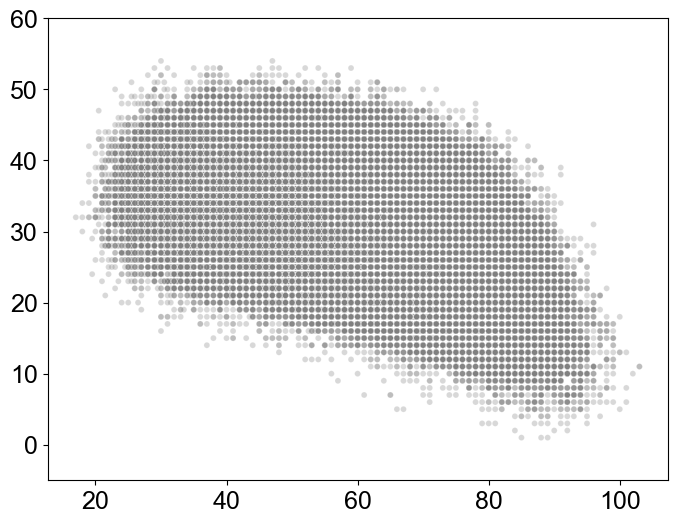

In [33]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=blosum62_matrix_test_seqs_triu, y=ham_dist_mat_test_seqs_bvae_triu, alpha=0.3, size=3, color='gray', legend=False)

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

plt.ylim(-5, 60)
# plt.title('BLOSUM62 vs Hamming')

(-5.0, 60.0)

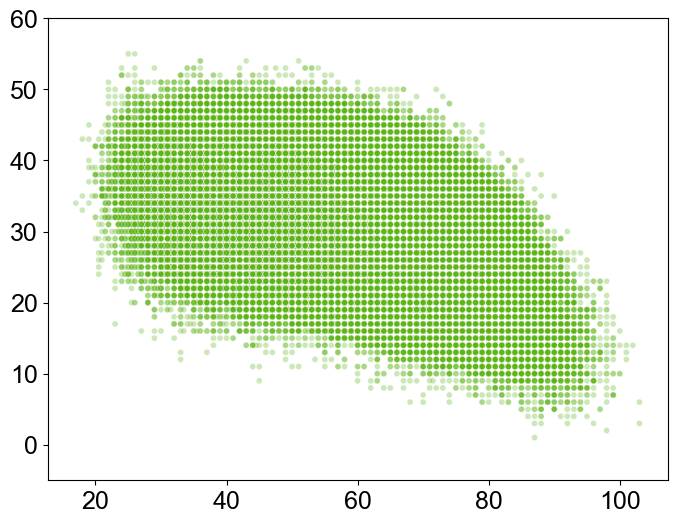

In [34]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=blosum62_matrix_test_seqs_triu, y=ham_dist_mat_test_seqs_esm_650m_triu, alpha=0.3, size=3, color='#5CB514', legend=False)

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

plt.ylim(-5, 60)
# plt.title('BLOSUM62 vs Hamming')

(-5.0, 60.0)

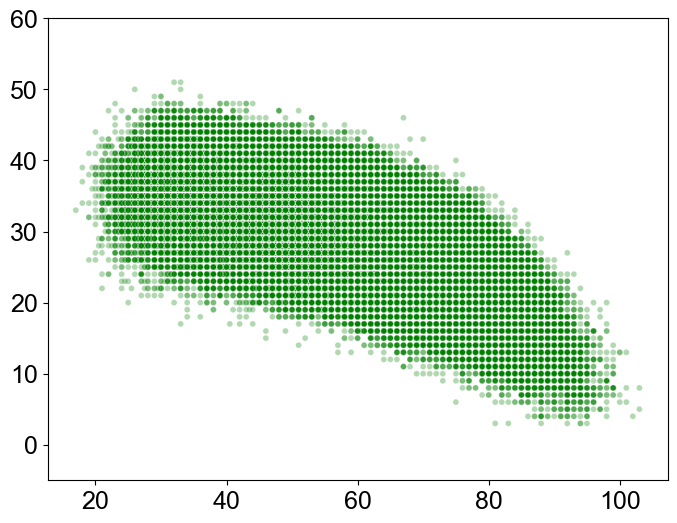

In [35]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=blosum62_matrix_test_seqs_triu, y=ham_dist_mat_test_seqs_esm_650m_opt_triu, alpha=0.3, size=3, color='green', legend=False)

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

plt.ylim(-5, 60)
# plt.title('BLOSUM62 vs Hamming')